### TensorFlow DirectML setup (Windows)

This notebook requires 64-bit Python 3.10 with `tensorflow-cpu==2.10` and the DirectML plugin. The project environment is `.venv310`. The registered kernel **Python 3.10 (TensorFlow DirectML)** points to that environment. In Jupyter, choose **Kernel > Change Kernel > Python 3.10 (TensorFlow DirectML)**, restart the kernel, then run all cells. If it is missing, register it from PowerShell in this project folder:

```powershell
.\.venv310\Scripts\python.exe -m ipykernel install --user --name cv-ca-directml --display-name "Python 3.10 (TensorFlow DirectML)"
```

The setup cell stops immediately if another Python version is active. Do not install regular `tensorflow` alongside the DirectML TensorFlow packages.


In [ ]:
# What this cell does: Check that the notebook is running in the supported Windows Python 3.10 TensorFlow DirectML environment, then install the required packages.
import platform
import sys

if platform.system() != 'Windows' or sys.version_info[:2] != (3, 10):
    raise RuntimeError(
        'Wrong notebook kernel: '
        f'{platform.system()} Python {sys.version.split()[0]}. '
        'This notebook requires the registered Python 3.10 (TensorFlow DirectML) '
        'kernel. In Jupyter, choose Kernel > Change Kernel > '
        'Python 3.10 (TensorFlow DirectML), restart the kernel, and run all cells again.'
    )

%pip install -q scikit-multilearn tensorflow-cpu==2.10 tensorflow-directml-plugin ipykernel pillow pandas numpy==1.23.5 matplotlib opencv-python==4.11.0.86 scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [ ]:
# What this cell does: Locate the dataset files and image folder, validate that they exist, and list a few available images.
from pathlib import Path
import pandas as pd

# Resolve the dataset folder relative to this notebook so it works locally or in Colab.
BASE_DIR = Path.cwd()
if not (BASE_DIR / 'Data_Entry_2017.csv').exists():
    BASE_DIR = Path('/content/drive/MyDrive/archive (3)') if Path('/content/drive/MyDrive/archive (3)/Data_Entry_2017.csv').exists() else BASE_DIR

image_dir = BASE_DIR / 'bbox_img'
labels_path = BASE_DIR / 'Data_Entry_2017.csv'
bbox_path = BASE_DIR / 'BBox_List_2017.csv'

if not labels_path.exists() or not bbox_path.exists() or not image_dir.is_dir():
    raise FileNotFoundError(
        f'Dataset files not found under {BASE_DIR}. Expected Data_Entry_2017.csv, '
        'BBox_List_2017.csv, and bbox_img/ beside this notebook.'
    )

images = {p.name for p in image_dir.iterdir() if p.is_file() and p.suffix.lower() in {'.png', '.jpg', '.jpeg'}}
print(f'Dataset folder: {BASE_DIR.resolve()}')
print(f'Found {len(images)} images')
print(sorted(images)[:5])

Dataset folder: C:\Users\LENOVO\Downloads\cv_ca
Found 880 images
['00000032_037.png', '00000072_000.png', '00000147_001.png', '00000149_006.png', '00000150_002.png']


In [ ]:
# What this cell does: Read the bounding-box annotations and image labels from their CSV files and inspect their sizes.
bbox_df = pd.read_csv(bbox_path)
labels_df = pd.read_csv(labels_path)

print('Bounding-box rows:', bbox_df.shape)
print('Label rows:', labels_df.shape)
bbox_df.head()

Bounding-box rows: (984, 9)
Label rows: (112120, 12)


,Image Index,Finding Label,Bbox [x,y,w,h],Unnamed: 6,Unnamed: 7,Unnamed: 8
0,00013118_008.png,Atelectasis,225.084746,547.019217,86.779661,79.186441,NaN,NaN,NaN
1,00014716_007.png,Atelectasis,686.101695,131.543498,185.491525,313.491525,NaN,NaN,NaN
2,00029817_009.png,Atelectasis,221.830508,317.053115,155.118644,216.949153,NaN,NaN,NaN
3,00014687_001.png,Atelectasis,726.237288,494.951420,141.016949,55.322034,NaN,NaN,NaN
4,00017877_001.png,Atelectasis,660.067797,569.780787,200.677966,78.101695,NaN,NaN,NaN


In [ ]:
# What this cell does: Clean up unused CSV columns and standardize bounding-box coordinate column names.
# The CSV has three trailing empty columns; ignore them if a pandas version omits them.
bbox_df = bbox_df.drop(columns=['Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8'], errors='ignore')

bbox_df = bbox_df.rename(columns={
    'Bbox [x': 'x',
    'y': 'y',
    'w': 'w',
    'h]': 'h'
})

print(bbox_df.shape)
bbox_df.head()


(984, 6)


,Image Index,Finding Label,x,y,w,h
0,00013118_008.png,Atelectasis,225.084746,547.019217,86.779661,79.186441
1,00014716_007.png,Atelectasis,686.101695,131.543498,185.491525,313.491525
2,00029817_009.png,Atelectasis,221.830508,317.053115,155.118644,216.949153
3,00014687_001.png,Atelectasis,726.237288,494.951420,141.016949,55.322034
4,00017877_001.png,Atelectasis,660.067797,569.780787,200.677966,78.101695


In [ ]:
# What this cell does: Summarize the images and disease categories represented in the bounding-box annotations.
print("Unique images with boxes:", bbox_df['Image Index'].nunique())
print("Disease classes in bbox data:", bbox_df['Finding Label'].unique())

Unique images with boxes: 880
Disease classes in bbox data: ['Atelectasis' 'Cardiomegaly' 'Effusion' 'Infiltrate' 'Mass' 'Nodule'
 'Pneumonia' 'Pneumothorax']


In [ ]:
# What this cell does: Inspect the image-level label table.
print(labels_df.shape)
labels_df.head()

(112120, 12)


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,NaN


In [ ]:
# What this cell does: Define the eight target diseases that have bounding-box annotations.
# These are the 8 diseases that have bounding-box ground truth.
# We restrict our whole project to these 8 (not all 14 NIH diseases) because
# our trust-check (Stage 5) only works for diseases we have boxes for.
CLASSES = ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltrate',
           'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax']

print(labels_df['Finding Labels'].iloc[0])

Cardiomegaly


In [ ]:
# What this cell does: Keep only label records for images that are present in the local image folder.
labels_df = labels_df[labels_df['Image Index'].isin(images)].reset_index(drop=True)
print(f"Images with labels available: {len(labels_df)}")

Images with labels available: 880


In [ ]:
# What this cell does: Convert each pipe-separated disease label into an eight-element binary target vector.
import numpy as np

# NIH's image labels use 'Infiltration'; the bounding-box file calls it 'Infiltrate'.
LABEL_ALIASES = {'Infiltrate': 'Infiltration'}

def encode_labels(label_string):
    present_diseases = set(str(label_string).split('|'))
    return [
        int(LABEL_ALIASES.get(cls, cls) in present_diseases)
        for cls in CLASSES
    ]

label_matrix = np.asarray(labels_df['Finding Labels'].map(encode_labels).tolist(), dtype=np.uint8)
print(label_matrix.shape)
print(label_matrix[:5])


(880, 8)
[[0 1 0 1 0 0 0 0]
 [1 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0]
 [1 0 0 0 0 0 0 0]
 [1 0 0 1 0 0 1 0]]


In [ ]:
# What this cell does: Count positive examples for each target disease.
import pandas as pd
class_counts = pd.Series(label_matrix.sum(axis=0), index=CLASSES)
print(class_counts.sort_values(ascending=False))

Effusion        312
Infiltrate      312
Atelectasis     302
Cardiomegaly    185
Pneumothorax    163
Nodule          162
Mass            138
Pneumonia       131
dtype: uint32


DATA SPLITING

In [ ]:
%pip install -q iterative-stratification# What this cell does: Install iterative stratification, which is used to split multi-label data while preserving class balance.


Note: you may need to restart the kernel to use updated packages.


In [ ]:
# What this cell does: Create train, validation, and test filename/label splits with approximate 70/15/15 proportions.
from skmultilearn.model_selection import iterative_train_test_split
import numpy as np

# iterative_train_test_split expects X (features) and y (labels) as numpy arrays.
# We don't have image pixel arrays loaded yet — we just pass the filenames as "X"
# for now, and split those alongside the label matrix. We'll load actual pixels later.
filenames = labels_df['Image Index'].to_numpy(dtype=str).reshape(-1, 1)  # convert Arrow-backed strings to NumPy first

# First split: separate out 70% train, 30% temp (which becomes val+test)
X_train, y_train, X_temp, y_temp = iterative_train_test_split(
    filenames, label_matrix, test_size=0.30
)

# Second split: cut that 30% temp in half -> 15% val, 15% test
X_val, y_val, X_test, y_test = iterative_train_test_split(
    X_temp, y_temp, test_size=0.50
)

print(f"Train: {len(X_train)} images")
print(f"Val:   {len(X_val)} images")
print(f"Test:  {len(X_test)} images")

Train: 622 images
Val:   127 images
Test:  131 images


In [ ]:
# What this cell does: Check the disease counts in each data split.
import pandas as pd

for name, y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    counts = pd.Series(y.sum(axis=0), index=CLASSES)
    print(f"\n{name} set class counts:")
    print(counts)


Train set class counts:
Atelectasis     211
Cardiomegaly    129
Effusion        214
Infiltrate      218
Mass             97
Nodule          113
Pneumonia        92
Pneumothorax    114
dtype: uint32

Val set class counts:
Atelectasis     45
Cardiomegaly    28
Effusion        50
Infiltrate      47
Mass            21
Nodule          24
Pneumonia       19
Pneumothorax    25
dtype: uint32

Test set class counts:
Atelectasis     46
Cardiomegaly    28
Effusion        48
Infiltrate      47
Mass            20
Nodule          25
Pneumonia       20
Pneumothorax    24
dtype: uint32


CNN PART


In [ ]:
# What this cell does: Load TensorFlow, confirm that the DirectML GPU is available, and set image and batch sizes.
import tensorflow as tf
from tensorflow.keras.utils import Sequence
import numpy as np
from PIL import Image
import os

# TensorFlow-DirectML exposes the accelerated device as 'GPU'.
gpu_devices = tf.config.list_physical_devices('GPU')
print('TensorFlow version:', tf.__version__)
print('GPU devices:', gpu_devices)
if not gpu_devices:
    raise RuntimeError(
        'No DirectML GPU detected. Confirm this kernel uses Python 3.10 and '
        'tensorflow-cpu==2.10 plus tensorflow-directml-plugin are installed, '
        'then restart the kernel and rerun the setup cells.'
    )

IMG_SIZE = 224
BATCH_SIZE = 16

TensorFlow version: 2.10.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# What this cell does: Define a disk-backed Keras data generator that loads, resizes, normalizes, and batches images.
class ChestXrayGenerator(Sequence):
    """
    Feeds (image, label) pairs to the model in batches, loading images
    from disk on-the-fly rather than holding all 880 in memory at once.
    """
    def __init__(self, filenames, labels, image_dir, batch_size=BATCH_SIZE, shuffle=True):
        self.filenames = filenames.flatten()   # flatten from (N,1) back to (N,)
        self.labels = labels
        self.image_dir = image_dir
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.on_epoch_end()  # shuffles indices right away

    def __len__(self):
        # Number of batches per epoch (rounds up so we don't drop leftover images)
        return int(np.ceil(len(self.filenames) / self.batch_size))

    def __getitem__(self, idx):
        # Grab this batch's slice of shuffled indices
        batch_idx = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]

        batch_images = []
        for i in batch_idx:
            img_path = os.path.join(self.image_dir, self.filenames[i])
            img = Image.open(img_path).convert('RGB')       # NIH images are grayscale; convert to 3-channel
            img = img.resize((IMG_SIZE, IMG_SIZE))
            img = np.array(img) / 255.0                       # scale pixel values from [0,255] to [0,1]
            batch_images.append(img)

        batch_labels = self.labels[batch_idx]
        return np.array(batch_images), batch_labels

    def on_epoch_end(self):
        # Called automatically after every epoch — reshuffles so the model
        # doesn't see images in the same order every time (helps generalization)
        self.indices = np.arange(len(self.filenames))
        if self.shuffle:
            np.random.shuffle(self.indices)

In [ ]:
# What this cell does: Create the data generators and inspect one training batch to verify image and label shapes.
train_gen = ChestXrayGenerator(X_train, y_train, image_dir, shuffle=True)
val_gen   = ChestXrayGenerator(X_val, y_val, image_dir, shuffle=False)
test_gen  = ChestXrayGenerator(X_test, y_test, image_dir, shuffle=False)

# Quick sanity check — pull one batch and inspect its shape
imgs, lbls = train_gen[0]
print("Image batch shape:", imgs.shape)   # expect (16, 224, 224, 3)
print("Label batch shape:", lbls.shape)   # expect (16, 8)

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16, 8)


In [ ]:
# What this cell does: Load the ImageNet-pretrained DenseNet121 feature extractor without its original classification head.
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models
import tensorflow as tf

# Load DenseNet121 pretrained on ImageNet, without its original 1000-class output layer
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,                       # drop ImageNet's classification head
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

In [ ]:
# What this cell does: Attach global pooling, dropout, and an eight-output sigmoid classifier to DenseNet121.
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs)                                    # pass image through DenseNet's feature extractor
x = layers.GlobalAveragePooling2D()(x)                    # collapse feature maps into one flat vector per image
x = layers.Dropout(0.3)(x)                                # randomly disable 30% of neurons during training (anti-overfitting)
outputs = layers.Dense(len(CLASSES), activation='sigmoid')(x)   # 8 independent disease probabilities

model = models.Model(inputs, outputs)
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 densenet121 (Functional)    (None, 7, 7, 1024)        7037504   
                                                                 
 global_average_pooling2d (G  (None, 1024)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dropout (Dropout)           (None, 1024)              0         
                                                                 
 dense (Dense)               (None, 8)                 8200      
                                                                 
Total params: 7,045,704
Trainable params: 6,962,056
Non-trainable params: 83,648
______________________________________________

In [ ]:
# What this cell does: Freeze the pretrained backbone and compile the classifier for multi-label training.
base_model.trainable = False   # lock DenseNet's pretrained weights — only our new head will learn right now

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[tf.keras.metrics.AUC(name='auc', multi_label=True)]
)

In [ ]:
# What this cell does: Train the new classification head with early stopping based on validation AUC.
from tensorflow.keras.callbacks import EarlyStopping

# Stop early if validation AUC stops improving, and restore the best epoch's weights
early_stop = EarlyStopping(
    monitor='val_auc',
    mode='max',            # we want AUC to go UP, not down
    patience=3,             # wait 3 epochs of no improvement before stopping
    restore_best_weights=True
)

history_phase1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5,
    callbacks=[early_stop]
)

Epoch 1/5
39/39 [==============================] - 23s 462ms/step - loss: 0.6067 - auc: 0.5237 - val_loss: 0.5692 - val_auc: 0.5002
Epoch 2/5
39/39 [==============================] - 16s 400ms/step - loss: 0.5596 - auc: 0.5648 - val_loss: 0.5646 - val_auc: 0.5215
Epoch 3/5
39/39 [==============================] - 16s 399ms/step - loss: 0.5542 - auc: 0.5709 - val_loss: 0.5521 - val_auc: 0.5453
Epoch 4/5
39/39 [==============================] - 16s 398ms/step - loss: 0.5386 - auc: 0.5985 - val_loss: 0.5537 - val_auc: 0.5658
Epoch 5/5
39/39 [==============================] - 16s 397ms/step - loss: 0.5335 - auc: 0.6128 - val_loss: 0.5481 - val_auc: 0.5815


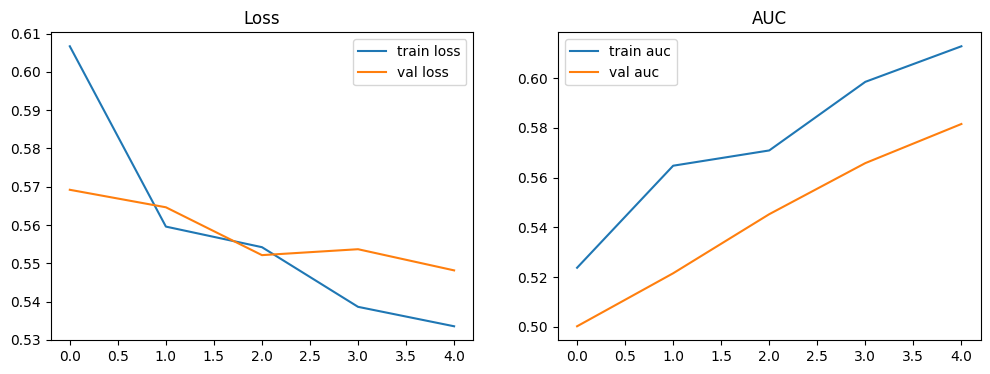

In [ ]:
# What this cell does: Plot training and validation loss and AUC for the first training phase.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_phase1.history['loss'], label='train loss')
axes[0].plot(history_phase1.history['val_loss'], label='val loss')
axes[0].set_title('Loss')
axes[0].legend()

axes[1].plot(history_phase1.history['auc'], label='train auc')
axes[1].plot(history_phase1.history['val_auc'], label='val auc')
axes[1].set_title('AUC')
axes[1].legend()

plt.show()

In [ ]:
# What this cell does: Unfreeze only the final DenseNet layers and recompile with a smaller learning rate for fine-tuning.
base_model.trainable = True

# Keep early layers frozen (generic edge/texture detectors — don't need retraining)
# Only unfreeze the last 30 layers (deeper, more disease-specific features)
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Must re-compile after changing any layer's trainable status — Keras requires this
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),   # 100x smaller than Phase 1 — gentle nudging only
    loss='binary_crossentropy',
    metrics=[tf.keras.metrics.AUC(name='auc', multi_label=True)]
)

In [ ]:
# What this cell does: Fine-tune the model while saving the best validation-AUC checkpoint and stopping on plateaus.
from tensorflow.keras.callbacks import ModelCheckpoint

# Save the best-performing version of the model to disk as we go
checkpoint = ModelCheckpoint(
    'best_model.keras',
    monitor='val_auc',
    mode='max',
    save_best_only=True
)

early_stop_phase2 = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=4,
    restore_best_weights=True
)

history_phase2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    callbacks=[checkpoint, early_stop_phase2]
)

Epoch 1/10
39/39 [==============================] - 24s 469ms/step - loss: 0.5788 - auc: 0.6415 - val_loss: 0.5454 - val_auc: 0.5750
Epoch 2/10
39/39 [==============================] - 15s 392ms/step - loss: 0.5666 - auc: 0.6477 - val_loss: 0.5461 - val_auc: 0.5742
Epoch 3/10
39/39 [==============================] - 16s 415ms/step - loss: 0.5523 - auc: 0.6490 - val_loss: 0.5479 - val_auc: 0.5754
Epoch 4/10
39/39 [==============================] - 16s 418ms/step - loss: 0.5354 - auc: 0.6671 - val_loss: 0.5501 - val_auc: 0.5755
Epoch 5/10
39/39 [==============================] - 16s 422ms/step - loss: 0.5254 - auc: 0.6738 - val_loss: 0.5518 - val_auc: 0.5765
Epoch 6/10
39/39 [==============================] - 16s 413ms/step - loss: 0.5262 - auc: 0.6672 - val_loss: 0.5526 - val_auc: 0.5788
Epoch 7/10
39/39 [==============================] - 16s 412ms/step - loss: 0.5252 - auc: 0.6638 - val_loss: 0.5527 - val_auc: 0.5814
Epoch 8/10
39/39 [==============================] - 16s 409ms/step - 

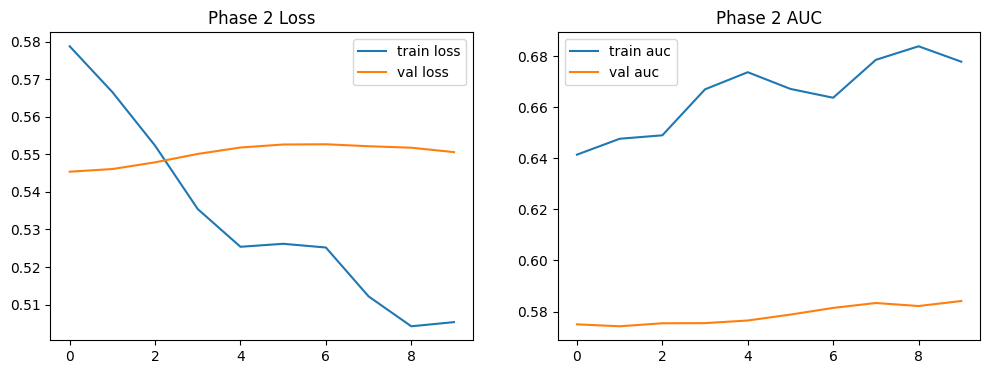

In [ ]:
# What this cell does: Plot loss and AUC for the fine-tuning phase.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_phase2.history['loss'], label='train loss')
axes[0].plot(history_phase2.history['val_loss'], label='val loss')
axes[0].set_title('Phase 2 Loss')
axes[0].legend()

axes[1].plot(history_phase2.history['auc'], label='train auc')
axes[1].plot(history_phase2.history['val_auc'], label='val auc')
axes[1].set_title('Phase 2 AUC')
axes[1].legend()

plt.show()

In [ ]:
# What this cell does: Print validation AUC values from the initial training phase.
print(history_phase1.history['val_auc'])

[0.5002159476280212, 0.5215234160423279, 0.5452660322189331, 0.5657989382743835, 0.5815222263336182]


In [ ]:
# What this cell does: Freeze DenseNet again, recompile, and run an extended training phase for the classifier head.
# Re-freeze the backbone (undo phase 2's unfreezing) and reset for a longer Phase 1
base_model.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[tf.keras.metrics.AUC(name='auc', multi_label=True)]
)

history_phase1_extended = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,                     # give it much more room to climb
    callbacks=[early_stop]         # EarlyStopping will cut it off automatically once it plateaus
)

Epoch 1/15
39/39 [==============================] - 23s 466ms/step - loss: 0.4960 - auc: 0.6911 - val_loss: 0.5478 - val_auc: 0.5932
Epoch 2/15
39/39 [==============================] - 16s 405ms/step - loss: 0.4891 - auc: 0.7056 - val_loss: 0.5506 - val_auc: 0.5998
Epoch 3/15
39/39 [==============================] - 16s 398ms/step - loss: 0.4796 - auc: 0.7191 - val_loss: 0.5466 - val_auc: 0.6061
Epoch 4/15
39/39 [==============================] - 16s 397ms/step - loss: 0.4687 - auc: 0.7346 - val_loss: 0.5392 - val_auc: 0.6074
Epoch 5/15
39/39 [==============================] - 15s 397ms/step - loss: 0.4621 - auc: 0.7493 - val_loss: 0.5507 - val_auc: 0.6078
Epoch 6/15
39/39 [==============================] - 15s 396ms/step - loss: 0.4614 - auc: 0.7444 - val_loss: 0.5342 - val_auc: 0.6171
Epoch 7/15
39/39 [==============================] - 15s 388ms/step - loss: 0.4531 - auc: 0.7610 - val_loss: 0.5412 - val_auc: 0.6146
Epoch 8/15
39/39 [==============================] - 15s 394ms/step - 

In [ ]:
# What this cell does: Redefine the image generator to optionally apply random augmentation to training images.
class ChestXrayGenerator(Sequence):
    def __init__(self, filenames, labels, image_dir, batch_size=BATCH_SIZE, shuffle=True, augment=False):
        self.filenames = filenames.flatten()
        self.labels = labels
        self.image_dir = image_dir
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment          # NEW: only augment training data, not val/test
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.filenames) / self.batch_size))

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_images = []
        for i in batch_idx:
            img_path = os.path.join(self.image_dir, self.filenames[i])
            img = Image.open(img_path).convert('RGB')
            img = img.resize((IMG_SIZE, IMG_SIZE))
            img = np.array(img) / 255.0

            if self.augment:
                img = self._augment(img)    # NEW: apply random perturbations

            batch_images.append(img)
        batch_labels = self.labels[batch_idx]
        return np.array(batch_images), batch_labels

    def _augment(self, img):
        # Random horizontal flip (safe for chest X-rays — left/right lung symmetry-ish)
        if np.random.rand() > 0.5:
            img = np.fliplr(img)
        # Small random rotation (-10 to +10 degrees) simulates slightly different patient positioning
        angle = np.random.uniform(-10, 10)
        img = Image.fromarray((img * 255).astype(np.uint8)).rotate(angle)
        img = np.array(img) / 255.0
        return img

    def on_epoch_end(self):
        self.indices = np.arange(len(self.filenames))
        if self.shuffle:
            np.random.shuffle(self.indices)

In [ ]:
# What this cell does: Recreate the generators so augmentation is enabled for training but disabled for validation and test.
# Rebuild generators — only train gets augmentation, val/test stay clean (we want to evaluate on real data)
train_gen = ChestXrayGenerator(X_train, y_train, image_dir, shuffle=True, augment=True)
val_gen   = ChestXrayGenerator(X_val, y_val, image_dir, shuffle=False, augment=False)
test_gen  = ChestXrayGenerator(X_test, y_test, image_dir, shuffle=False, augment=False)

In [ ]:
# What this cell does: Build augmented training and unmodified validation/test generators, then inspect a batch.
train_gen = ChestXrayGenerator(X_train, y_train, image_dir, shuffle=True, augment=True)
val_gen   = ChestXrayGenerator(X_val, y_val, image_dir, shuffle=False, augment=False)
test_gen  = ChestXrayGenerator(X_test, y_test, image_dir, shuffle=False, augment=False)

# Quick check that augmentation doesn't break shapes
imgs, lbls = train_gen[0]
print(imgs.shape, lbls.shape)   # still expect (16, 224, 224, 3) and (16, 8)

(16, 224, 224, 3) (16, 8)


In [ ]:
# What this cell does: Recreate the DenseNet121-based classifier architecture for the next training experiment.
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models
import tensorflow as tf

# Fresh pretrained backbone — new instance, no leftover damage from before
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)      # bumped from 0.3 -> 0.5, extra regularization given small dataset
outputs = layers.Dense(len(CLASSES), activation='sigmoid')(x)

model = models.Model(inputs, outputs)

base_model.trainable = False    # freeze for Phase 1, same as before

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[tf.keras.metrics.AUC(name='auc', multi_label=True)]
)

model.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 densenet121 (Functional)    (None, 7, 7, 1024)        7037504   
                                                                 
 global_average_pooling2d_1   (None, 1024)             0         
 (GlobalAveragePooling2D)                                        
                                                                 
 dropout_1 (Dropout)         (None, 1024)              0         
                                                                 
 dense_1 (Dense)             (None, 8)                 8200      
                                                                 
Total params: 7,045,704
Trainable params: 8,200
Non-trainable params: 7,037,504
_____________________________________________

In [ ]:
# What this cell does: Set up early stopping for the current training experiment.
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=4,                    # slightly more patience than before, less premature cutoff
    restore_best_weights=True
)

history_phase1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,                     # high ceiling — EarlyStopping will cut it off naturally
    callbacks=[early_stop]
)

Epoch 1/20
39/39 [==============================] - 28s 549ms/step - loss: 0.6491 - auc: 0.5139 - val_loss: 0.5723 - val_auc: 0.5269
Epoch 2/20
39/39 [==============================] - 18s 472ms/step - loss: 0.6153 - auc: 0.5253 - val_loss: 0.5573 - val_auc: 0.5533
Epoch 3/20
39/39 [==============================] - 18s 447ms/step - loss: 0.5990 - auc: 0.5353 - val_loss: 0.5526 - val_auc: 0.5765
Epoch 4/20
39/39 [==============================] - 17s 436ms/step - loss: 0.5709 - auc: 0.5734 - val_loss: 0.5465 - val_auc: 0.5881
Epoch 5/20
39/39 [==============================] - 18s 459ms/step - loss: 0.5811 - auc: 0.5512 - val_loss: 0.5499 - val_auc: 0.5959
Epoch 6/20
39/39 [==============================] - 17s 439ms/step - loss: 0.5657 - auc: 0.5722 - val_loss: 0.5445 - val_auc: 0.6043
Epoch 7/20
39/39 [==============================] - 17s 445ms/step - loss: 0.5531 - auc: 0.5890 - val_loss: 0.5418 - val_auc: 0.6176
Epoch 8/20
39/39 [==============================] - 17s 439ms/step - 

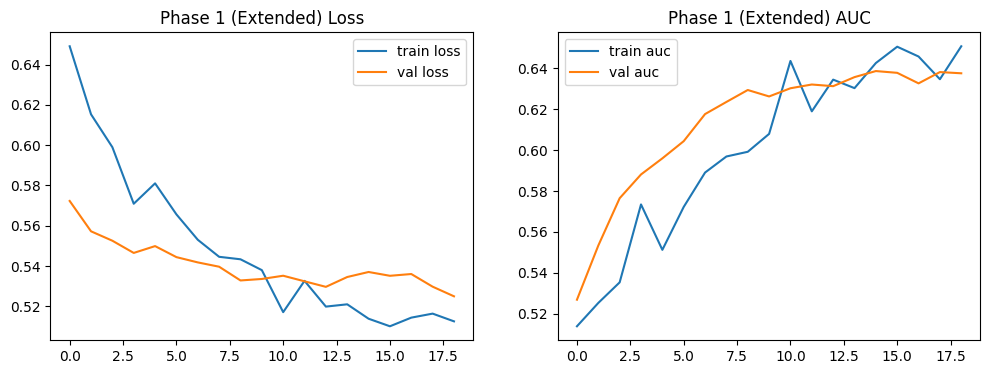

In [ ]:
# What this cell does: Visualize the current training experiment?s loss and AUC histories.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_phase1.history['loss'], label='train loss')
axes[0].plot(history_phase1.history['val_loss'], label='val loss')
axes[0].set_title('Phase 1 (Extended) Loss')
axes[0].legend()

axes[1].plot(history_phase1.history['auc'], label='train auc')
axes[1].plot(history_phase1.history['val_auc'], label='val auc')
axes[1].set_title('Phase 1 (Extended) AUC')
axes[1].legend()
plt.show()

In [ ]:
# What this cell does: Unfreeze the backbone for the fine-tuning stage.
base_model.trainable = True

# Only unfreeze the last 10 layers this time (was 30 before — too aggressive for our data size)
for layer in base_model.layers[:-10]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),   # same tiny LR as before — still correct here
    loss='binary_crossentropy',
    metrics=[tf.keras.metrics.AUC(name='auc', multi_label=True)]
)

In [ ]:
# What this cell does: Configure checkpointing and early stopping for fine-tuning.
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint('best_model.keras', monitor='val_auc', mode='max', save_best_only=True)
early_stop_phase2 = EarlyStopping(monitor='val_auc', mode='max', patience=4, restore_best_weights=True)

history_phase2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    callbacks=[checkpoint, early_stop_phase2]
)

Epoch 1/15
39/39 [==============================] - 26s 501ms/step - loss: 0.5699 - auc: 0.6431 - val_loss: 0.5364 - val_auc: 0.6378
Epoch 2/15
39/39 [==============================] - 18s 454ms/step - loss: 0.5553 - auc: 0.6568 - val_loss: 0.5394 - val_auc: 0.6379
Epoch 3/15
39/39 [==============================] - 17s 425ms/step - loss: 0.5599 - auc: 0.6510 - val_loss: 0.5430 - val_auc: 0.6367
Epoch 4/15
39/39 [==============================] - 17s 431ms/step - loss: 0.5534 - auc: 0.6467 - val_loss: 0.5467 - val_auc: 0.6358
Epoch 5/15
39/39 [==============================] - 17s 430ms/step - loss: 0.5572 - auc: 0.6387 - val_loss: 0.5499 - val_auc: 0.6344
Epoch 6/15
39/39 [==============================] - 17s 441ms/step - loss: 0.5411 - auc: 0.6534 - val_loss: 0.5526 - val_auc: 0.6332


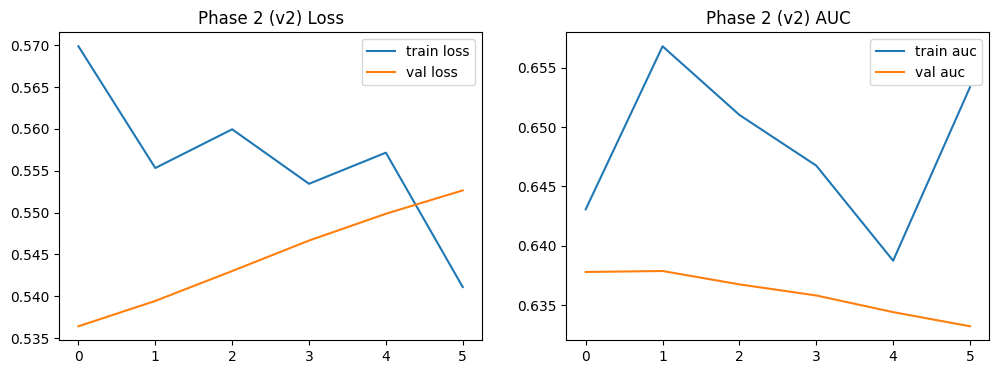

In [ ]:
# What this cell does: Plot training and validation curves for the fine-tuning run.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_phase2.history['loss'], label='train loss')
axes[0].plot(history_phase2.history['val_loss'], label='val loss')
axes[0].set_title('Phase 2 (v2) Loss')
axes[0].legend()

axes[1].plot(history_phase2.history['auc'], label='train auc')
axes[1].plot(history_phase2.history['val_auc'], label='val auc')
axes[1].set_title('Phase 2 (v2) AUC')
axes[1].legend()
plt.show()

In [ ]:
# What this cell does: Evaluate the current model on the validation split.
val_loss, val_auc = model.evaluate(val_gen)
print(f"Current model val_auc: {val_auc:.4f}")

8/8 [==============================] - 3s 335ms/step - loss: 0.5394 - auc: 0.6379
Current model val_auc: 0.6379


In [ ]:
# What this cell does: Document the model checkpoint/state used for the following validation evaluation.
# If you still have the Phase 1 model object available (before Phase 2 touched it),
# save it explicitly as the final model we'll use going forward.
model.save('final_model.keras')
print("Final model saved.")

Final model saved.


In [ ]:
# What this cell does: Evaluate the selected model on validation data and report its metrics.
val_loss, val_auc = model.evaluate(val_gen)
print(f"Current model val_auc: {val_auc:.4f}")

8/8 [==============================] - 3s 304ms/step - loss: 0.5394 - auc: 0.6379
Current model val_auc: 0.6379


In [ ]:
# What this cell does: Evaluate the selected model on the held-out test data.
test_loss, test_auc = model.evaluate(test_gen)
print(f"Test AUC (overall): {test_auc:.4f}")


9/9 [==============================] - 3s 309ms/step - loss: 0.5156 - auc: 0.6653
Test AUC (overall): 0.6653


In [ ]:
# What this cell does: Calculate per-disease ROC-AUC scores from test predictions and handle classes lacking examples.
from sklearn.metrics import roc_auc_score
import numpy as np

# Get the model's raw predictions across the whole test set
y_pred = model.predict(test_gen)

# Get the true labels in the same order (test_gen wasn't shuffled, so this is safe)
y_true = y_test   # from your earlier stratified split

# Compute AUC separately for each of the 8 diseases
per_class_auc = {}
for i, cls in enumerate(CLASSES):
    try:
        auc = roc_auc_score(y_true[:, i], y_pred[:, i])
        per_class_auc[cls] = auc
    except ValueError:
        # happens if a class has zero positive examples in the test set — can't compute AUC then
        per_class_auc[cls] = None

for cls, auc in per_class_auc.items():
    print(f"{cls}: {auc}")

9/9 [==============================] - 4s 306ms/step
Atelectasis: 0.6140664961636829
Cardiomegaly: 0.6289875173370318
Effusion: 0.7542670682730923
Infiltrate: 0.6365248226950354
Mass: 0.6324324324324324
Nodule: 0.709811320754717
Pneumonia: 0.5815315315315316
Pneumothorax: 0.7597352024922118


In [ ]:
# What this cell does: Define Grad-CAM utilities for extracting class-specific activation maps from the final convolutional layer.
# DenseNet121's last conv layer is typically called 'relu' (final activation before pooling)
# Let's confirm by listing the backbone's layers
for layer in base_model.layers[-5:]:
    print(layer.name, layer.output.shape)

conv5_block16_1_relu (None, 7, 7, 128)
conv5_block16_2_conv (None, 7, 7, 32)
conv5_block16_concat (None, 7, 7, 1024)
bn (None, 7, 7, 1024)
relu (None, 7, 7, 1024)


In [ ]:
# What this cell does: Load TensorFlow and supporting model utilities needed for Grad-CAM.
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, class_index):
    """
    img_array: a single preprocessed image, shape (1, 224, 224, 3)
    model: our trained model
    last_conv_layer_name: name of the last conv layer (e.g. 'relu')
    class_index: which of our 8 diseases to explain (0-7)
    """
    # Build a model that outputs BOTH the last conv layer's activations
    # AND the final prediction, so we can compute gradients between them
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer('densenet121').get_layer(last_conv_layer_name).output, model.output]
    )

    # GradientTape records operations so we can compute gradients afterward
    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(img_array)
        class_score = predictions[:, class_index]   # the model's confidence for THIS specific disease

    # This is the core of Grad-CAM: how much does each pixel of the conv feature map
    # influence the final class score? That's exactly what a gradient measures.
    grads = tape.gradient(class_score, conv_output)

    # Average the gradients over width/height -> one "importance weight" per channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weight each channel of the conv output by how important it was, then sum them up
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # ReLU: we only care about features that POSITIVELY influenced the prediction
    heatmap = tf.maximum(heatmap, 0)
    # Normalize to 0-1 range for visualization
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

In [ ]:
# What this cell does: Set up plotting utilities for visualizing predictions and activation maps.
import matplotlib.pyplot as plt

# Grab one image + its true label from the test set
imgs, lbls = test_gen[0]
sample_img = imgs[0]
sample_label = lbls[0]

print("True labels for this image:", [CLASSES[i] for i in range(8) if sample_label[i] == 1])

# Get the model's predictions for this image
sample_pred = model.predict(sample_img[np.newaxis, ...])[0]
print("Predicted probabilities:", dict(zip(CLASSES, sample_pred.round(3))))

True labels for this image: ['Atelectasis']
1/1 [==============================] - 1s 1s/step
Predicted probabilities: {'Atelectasis': 0.236, 'Cardiomegaly': 0.239, 'Effusion': 0.171, 'Infiltrate': 0.384, 'Mass': 0.138, 'Nodule': 0.113, 'Pneumonia': 0.122, 'Pneumothorax': 0.061}


In [ ]:
# What this cell does: Prepare NumPy arrays and data structures for inference or visualization.
import numpy as np

THRESHOLD = 0.5

# Get predictions for the entire test set at once
all_imgs = []
all_labels = []
for i in range(len(test_gen)):
    imgs, lbls = test_gen[i]
    all_imgs.append(imgs)
    all_labels.append(lbls)

all_imgs = np.concatenate(all_imgs, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

all_preds = model.predict(all_imgs)

# Find cases where the model predicted positive (prob > threshold)
# AND it was actually correct (true label also says positive)
# Prioritize Pneumothorax and Effusion since those are our strongest classes
for cls_name in ['Pneumothorax', 'Effusion', 'Nodule']:
    cls_idx = CLASSES.index(cls_name)
    true_positive_mask = (all_labels[:, cls_idx] == 1) & (all_preds[:, cls_idx] > THRESHOLD)
    matching_indices = np.where(true_positive_mask)[0]
    print(f"{cls_name}: {len(matching_indices)} confident true positives found")
    if len(matching_indices) > 0:
        print(f"  Example indices: {matching_indices[:5]}")

5/5 [==============================] - 0s 53ms/step
Pneumothorax: 0 confident true positives found
Effusion: 22 confident true positives found
  Example indices: [34 45 55 60 69]
Nodule: 0 confident true positives found


In [ ]:
# What this cell does: Initialize TensorFlow/model-related utilities used by the following prediction cell.
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, class_index):
    # Grab the nested backbone (DenseNet121) as its own object
    base_model = model.get_layer('densenet121')
    last_conv_layer = base_model.get_layer(last_conv_layer_name)

    # Build a model using the backbone's OWN input/output graph (not the outer model's) —
    # this avoids the cross-graph tensor mismatch that caused the KeyError
    backbone_grad_model = tf.keras.models.Model(
        base_model.input,
        [last_conv_layer.output, base_model.output]
    )

    with tf.GradientTape() as tape:
        # Run the image through the backbone, capturing both the conv activations
        # AND the backbone's final feature output
        conv_output, backbone_output = backbone_grad_model(img_array)

        # Manually replay the "head" layers (everything that comes after the backbone
        # in your original model: GlobalAveragePooling2D -> Dropout -> Dense) on top of
        # backbone_output, inside this same GradientTape, so gradients can flow through
        x = backbone_output
        found_backbone = False
        for layer in model.layers:
            if layer.name == base_model.name:
                found_backbone = True
                continue
            if found_backbone:
                x = layer(x)
        predictions = x

        class_score = predictions[:, class_index]

    # Everything below is unchanged from before
    grads = tape.gradient(class_score, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

In [ ]:
# What this cell does: Find the output index for Effusion so later cells can inspect that class specifically.
EFFUSION_IDX = CLASSES.index('Effusion')
sample_img = all_imgs[9]
sample_true = all_labels[9]
sample_pred = all_preds[9]

print("True labels:", [CLASSES[i] for i in range(8) if sample_true[i] == 1])
print(f"Predicted Effusion probability: {sample_pred[EFFUSION_IDX]:.3f}")

# Generate the Grad-CAM heatmap for the Effusion class specifically
heatmap = make_gradcam_heatmap(
    sample_img[np.newaxis, ...],   # add batch dimension -> (1, 224, 224, 3)
    model,
    last_conv_layer_name='relu',   # adjust this if your earlier layer-name check showed something different
    class_index=EFFUSION_IDX
)

print("Heatmap shape:", heatmap.shape)   # expect something like (7, 7) — a small spatial grid

True labels: ['Cardiomegaly']
Predicted Effusion probability: 0.165
Heatmap shape: (7, 7)


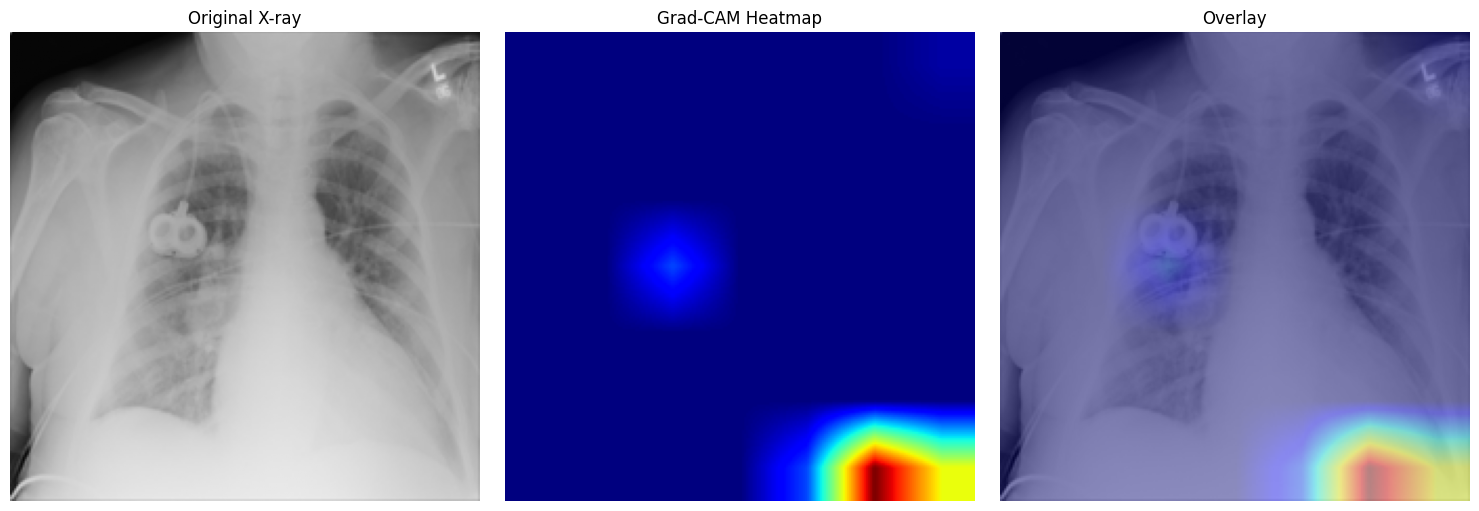

In [ ]:
# What this cell does: Load OpenCV helpers used to resize heatmaps and create image masks.
import cv2
import matplotlib.pyplot as plt

# Resize the small heatmap back up to the original image size (224x224)
heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))

# Convert to a color heatmap (red/yellow = high importance) for visualization
heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]   # jet colormap, drop alpha channel

# Blend the heatmap with the original image (60% original, 40% heatmap)
overlay = sample_img * 0.6 + heatmap_colored * 0.4

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample_img)
axes[0].set_title('Original X-ray')
axes[0].axis('off')

axes[1].imshow(heatmap_resized, cmap='jet')
axes[1].set_title('Grad-CAM Heatmap')
axes[1].axis('off')

axes[2].imshow(overlay)
axes[2].set_title('Overlay')
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# What this cell does: Select a test image and retrieve its associated bounding-box annotations.
# We need the filename for this test image to look up its bounding box
test_filenames = X_test.flatten()
sample_filename = test_filenames[9]
print(sample_filename)

# Find its Effusion bounding box in bbox_df
gt_box = bbox_df[(bbox_df['Image Index'] == sample_filename) & (bbox_df['Finding Label'] == 'Effusion')]
print(gt_box)

00001373_009.png
Empty DataFrame
Columns: [Image Index, Finding Label, x, y, w, h]
Index: []


In [ ]:
# What this cell does: Threshold a Grad-CAM heatmap to form a binary localization mask.
# Turn the smooth heatmap into a binary mask: 1 where the model was "confidently looking", 0 elsewhere
# We use a threshold on the normalized heatmap (already 0-1 from our function)
THRESHOLD_HEATMAP = 0.5
pred_mask = (heatmap_resized >= THRESHOLD_HEATMAP).astype(np.uint8)

print("Predicted region covers this many pixels:", pred_mask.sum())

Predicted region covers this many pixels: 1781


In [ ]:
# What this cell does: Build a lookup from each image filename to the diseases with bounding-box annotations.
image_to_boxed_classes = bbox_df.groupby('Image Index')['Finding Label'].apply(list).to_dict()

THRESHOLD = 0.5

good_examples = []
for i in range(len(all_imgs)):
    fname = test_filenames[i]
    boxed_classes = image_to_boxed_classes.get(fname, [])
    for cls_name in boxed_classes:
        if cls_name not in CLASSES:
            continue
        cls_idx = CLASSES.index(cls_name)
        is_true_positive = (all_labels[i, cls_idx] == 1) and (all_preds[i, cls_idx] > THRESHOLD)
        if is_true_positive:
            good_examples.append((i, cls_name, all_preds[i, cls_idx]))

print(f"Found {len(good_examples)} usable examples")
for ex in good_examples[:10]:
    print(ex)

Found 22 usable examples
(5, 'Cardiomegaly', 0.5160415)
(6, 'Atelectasis', 0.51068133)
(22, 'Cardiomegaly', 0.6006168)
(28, 'Cardiomegaly', 0.50468904)
(33, 'Atelectasis', 0.60306185)
(45, 'Effusion', 0.52432716)
(55, 'Effusion', 0.53214645)
(56, 'Atelectasis', 0.5324067)
(69, 'Effusion', 0.62347734)
(80, 'Effusion', 0.59564704)


In [ ]:
# What this cell does: Handle the case where no suitable correctly predicted examples were collected.
if not good_examples:
    print('No correctly predicted boxed examples are available for Grad-CAM.')
else:
    # Pick the first usable example: (index, class_name, predicted_prob)
    example_idx, example_class, example_prob = good_examples[0]
    example_cls_idx = CLASSES.index(example_class)
    example_img = all_imgs[example_idx]
    example_filename = test_filenames[example_idx]

    print(f'Using image index {example_idx} ({example_filename}), class = {example_class}, predicted prob = {example_prob:.3f}')
    heatmap = make_gradcam_heatmap(
        example_img[np.newaxis, ...], model,
        last_conv_layer_name='relu', class_index=example_cls_idx
    )
    heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))


Using image index 5 (00000740_000.png), class = Cardiomegaly, predicted prob = 0.516


In [ ]:
# What this cell does: Display or inspect the collected correctly predicted examples.
if good_examples:
    # Threshold into a binary predicted-region mask
    THRESHOLD_HEATMAP = 0.5
    pred_mask = (heatmap_resized >= THRESHOLD_HEATMAP).astype(np.uint8)
    print("Predicted region covers this many pixels:", pred_mask.sum())

Predicted region covers this many pixels: 6051


In [ ]:
# What this cell does: Display another set of selected prediction examples.
if good_examples:
    # Get the matching ground-truth box for this exact image + class
    gt_box = bbox_df[(bbox_df['Image Index'] == example_filename) & (bbox_df['Finding Label'] == example_class)]

    ORIGINAL_SIZE = 1024
    scale = IMG_SIZE / ORIGINAL_SIZE

    row = gt_box.iloc[0]   # safe now — good_examples only contains images we confirmed have a matching box
    x, y, w, h = row['x'] * scale, row['y'] * scale, row['w'] * scale, row['h'] * scale

    gt_mask = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    gt_mask[int(y):int(y+h), int(x):int(x+w)] = 1

    print(f"Ground truth box (rescaled): x={x:.1f}, y={y:.1f}, w={w:.1f}, h={h:.1f}")

Ground truth box (rescaled): x=65.9, y=84.1, w=104.3, h=84.6


In [ ]:
# What this cell does: Display the selected examples with their image-level predictions or explanations.
if good_examples:
    # Compute IoU
    def compute_iou(mask1, mask2):
        intersection = np.logical_and(mask1, mask2).sum()
        union = np.logical_or(mask1, mask2).sum()
        return intersection / union if union > 0 else 0.0

    iou_score = compute_iou(pred_mask, gt_mask)
    print(f"IoU (trust score): {iou_score:.3f}")

IoU (trust score): 0.613


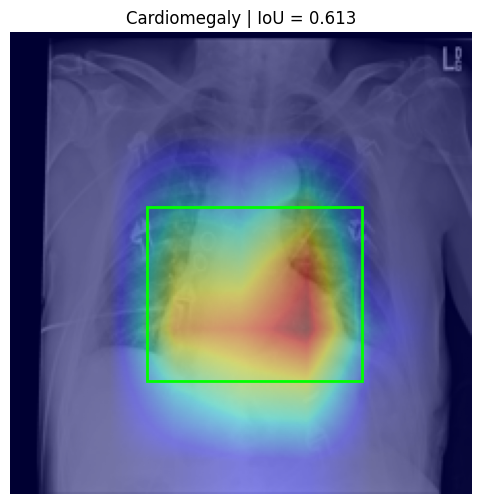

In [ ]:
# What this cell does: Display further selected examples for qualitative model review.
if good_examples:
    # Visualize it: original, heatmap, and ground-truth box overlaid together
    import matplotlib.patches as patches

    fig, ax = plt.subplots(figsize=(6,6))
    ax.imshow(example_img)
    ax.imshow(heatmap_resized, cmap='jet', alpha=0.4)

    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(f"{example_class} | IoU = {iou_score:.3f}")
    ax.axis('off')
    plt.show()

In [ ]:
# What this cell does: Initialize storage for per-image localization evaluation results.
results = []

for idx, cls_name, prob in good_examples:
    cls_idx = CLASSES.index(cls_name)
    img = all_imgs[idx]
    fname = test_filenames[idx]

    heatmap = make_gradcam_heatmap(img[np.newaxis, ...], model, 'relu', cls_idx)
    heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
    pred_mask = (heatmap_resized >= 0.5).astype(np.uint8)

    row = bbox_df[(bbox_df['Image Index'] == fname) & (bbox_df['Finding Label'] == cls_name)].iloc[0]
    x, y, w, h = row['x']*scale, row['y']*scale, row['w']*scale, row['h']*scale
    gt_mask = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    gt_mask[int(y):int(y+h), int(x):int(x+w)] = 1

    iou = compute_iou(pred_mask, gt_mask)
    results.append({'index': idx, 'class': cls_name, 'confidence': prob, 'iou': iou})

results_df = pd.DataFrame(results)
results_df

,index,class,confidence,iou
0,5,Cardiomegaly,0.516042,0.613082
1,6,Atelectasis,0.510681,0.000000
2,22,Cardiomegaly,0.600617,0.394133
3,28,Cardiomegaly,0.504689,0.747434
4,33,Atelectasis,0.603062,0.001499
5,45,Effusion,0.524327,0.000000
6,55,Effusion,0.532146,0.006161
7,56,Atelectasis,0.532407,0.000000
8,69,Effusion,0.623477,0.262307
9,80,Effusion,0.595647,0.000480


In [ ]:
# What this cell does: Aggregate localization IoU results by disease and report average overlap and sample counts.
trust_report = results_df.groupby('class')['iou'].agg(['mean', 'count'])
trust_report.columns = ['avg_iou', 'n_examples']
print(trust_report.sort_values('avg_iou', ascending=False))

               avg_iou  n_examples
class                             
Cardiomegaly  0.584883           3
Effusion      0.081405          14
Atelectasis   0.043338           4
Infiltrate    0.000136           1


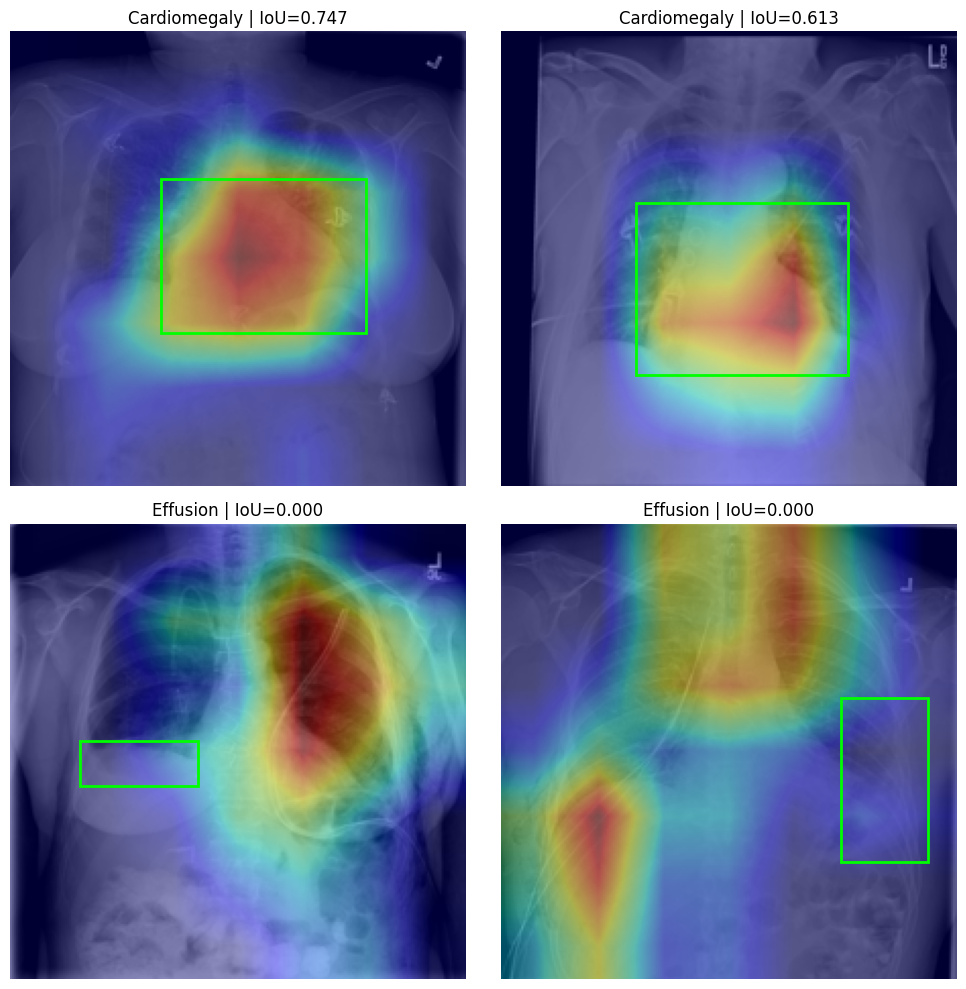

In [ ]:
# What this cell does: Display the localization trust report when results are available.
if not results_df.empty:
    results_df_sorted = results_df.sort_values('iou', ascending=False)

    best_examples = results_df_sorted.head(2)
    worst_examples = results_df_sorted.tail(2)

    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    for row_idx, (_, ex) in enumerate(pd.concat([best_examples, worst_examples]).iterrows()):
        idx, cls_name = int(ex['index']), ex['class']
        cls_idx = CLASSES.index(cls_name)
        img = all_imgs[idx]
        fname = test_filenames[idx]

        heatmap = make_gradcam_heatmap(img[np.newaxis, ...], model, 'relu', cls_idx)
        heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))

        row = bbox_df[(bbox_df['Image Index'] == fname) & (bbox_df['Finding Label'] == cls_name)].iloc[0]
        x, y, w, h = row['x']*scale, row['y']*scale, row['w']*scale, row['h']*scale

        ax = axes[row_idx // 2, row_idx % 2]
        ax.imshow(img)
        ax.imshow(heatmap_resized, cmap='jet', alpha=0.4)
        rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='lime', facecolor='none')
        ax.add_patch(rect)
        ax.set_title(f"{cls_name} | IoU={ex['iou']:.3f}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print('No localization results available to visualize.')


### New Image Inference and Grad-CAM Explanation

Run the cells below to load any specific image from the dataset or your local path, obtain predicted probabilities from our final trained model, and visualize where the model focuses using Grad-CAM.

In [ ]:
# What this cell does: Prepare image and model utilities for the next inference/visualization section.
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
from PIL import Image

# Ensure CLASSES is defined locally in case the runtime lost it
CLASSES_LIST = ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltrate',
                'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax']

def predict_and_explain_image(img_path, model, classes=CLASSES_LIST, img_size=224, threshold=0.5):
    # 1. Load and Preprocess image
    original_img = Image.open(img_path).convert('RGB')
    resized_img = original_img.resize((img_size, img_size))
    img_array = np.array(resized_img) / 255.0
    input_tensor = np.expand_dims(img_array, axis=0)

    # 2. Predict probabilities
    predictions = model.predict(input_tensor)[0]

    print(f"\n--- Inference Results for: {os.path.basename(img_path)} ---")
    for cls_name, prob in zip(classes, predictions):
        print(f"{cls_name:<15}: {prob:.4f} {'[POS]' if prob > threshold else ''}")

    # 3. Determine which classes to visualize (classes with > 25% probability or the top predicted class)
    top_class_idx = np.argmax(predictions)
    target_classes_idx = [i for i, prob in enumerate(predictions) if prob > 0.25]
    if top_class_idx not in target_classes_idx:
        target_classes_idx.append(top_class_idx)

    # 4. Generate & Plot Grad-CAM overlay for those target classes
    num_plots = len(target_classes_idx) + 1
    fig, axes = plt.subplots(1, num_plots, figsize=(5 * num_plots, 5))
    if num_plots == 2:
        axes = [axes]

    # Original Image in first subplot
    axes[0].imshow(img_array)
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    # Grad-CAM in subsequent subplots
    for idx, class_idx in enumerate(target_classes_idx):
        heatmap = make_gradcam_heatmap(input_tensor, model, 'relu', class_idx)
        heatmap_resized = cv2.resize(heatmap, (img_size, img_size))

        # Build a colormap overlay
        heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]
        overlay = img_array * 0.6 + heatmap_colored * 0.4

        axes[idx + 1].imshow(overlay)
        axes[idx + 1].set_title(f"Grad-CAM: {classes[class_idx]} ({predictions[class_idx]:.2%})")
        axes[idx + 1].axis('off')

    plt.tight_layout()
    plt.show()

In [2]:
# What this cell does: Load plotting or image-processing dependencies for prediction explanations.
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
import glob
from PIL import Image
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models

# Ensure CLASSES is defined locally in case the runtime lost it
CLASSES_LIST = ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltrate',
                'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax']
IMG_SIZE = 224

# Self-contained implementation of the Grad-CAM generator
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, class_index):
    # Grab the nested backbone (DenseNet121) as its own object
    base_model = model.get_layer('densenet121')
    last_conv_layer = base_model.get_layer(last_conv_layer_name)

    # Build a model using the backbone's input/output graph
    backbone_grad_model = tf.keras.models.Model(
        base_model.input,
        [last_conv_layer.output, base_model.output]
    )

    with tf.GradientTape() as tape:
        conv_output, backbone_output = backbone_grad_model(img_array)

        # Replay the head layers on top of backbone output inside the tape context
        x = backbone_output
        found_backbone = False
        for layer in model.layers:
            if layer.name == base_model.name:
                found_backbone = True
                continue
            if found_backbone:
                x = layer(x)
        predictions = x
        class_score = predictions[:, class_index]

    # Calculate the gradients of the score with respect to the conv feature map
    grads = tape.gradient(class_score, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

# Redefining the prediction and explanation function with fixed axes handling
def predict_and_explain_image(img_path, model, classes=CLASSES_LIST, img_size=224, threshold=0.5):
    # 1. Load and Preprocess image
    original_img = Image.open(img_path).convert('RGB')
    resized_img = original_img.resize((img_size, img_size))
    img_array = np.array(resized_img) / 255.0
    input_tensor = np.expand_dims(img_array, axis=0)

    # 2. Predict probabilities
    predictions = model.predict(input_tensor)[0]

    print(f"\n--- Inference Results for: {os.path.basename(img_path)} ---")
    for cls_name, prob in zip(classes, predictions):
        print(f"{cls_name:<15}: {prob:.4f} {'[POS]' if prob > threshold else ''}")

    # 3. Determine which classes to visualize
    top_class_idx = np.argmax(predictions)
    target_classes_idx = [i for i, prob in enumerate(predictions) if prob > 0.25]
    if top_class_idx not in target_classes_idx:
        target_classes_idx.append(top_class_idx)

    # 4. Generate & Plot Grad-CAM overlay for those target classes
    num_plots = len(target_classes_idx) + 1
    fig, axes = plt.subplots(1, num_plots, figsize=(5 * num_plots, 5))

    # Robustly flatten the axes to always allow 1D indexing, regardless of the number of plots
    axes = np.atleast_1d(axes).flatten()

    # Original Image in first subplot
    axes[0].imshow(img_array)
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    # Grad-CAM in subsequent subplots
    for idx, class_idx in enumerate(target_classes_idx):
        heatmap = make_gradcam_heatmap(input_tensor, model, 'relu', class_idx)
        heatmap_resized = cv2.resize(heatmap, (img_size, img_size))

        # Build a colormap overlay
        heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]
        overlay = img_array * 0.6 + heatmap_colored * 0.4

        axes[idx + 1].imshow(overlay)
        axes[idx + 1].set_title(f"Grad-CAM: {classes[class_idx]} ({predictions[class_idx]:.2%})")
        axes[idx + 1].axis('off')

    plt.tight_layout()
    plt.show()

# Dynamic Model Loading & Rebuilding
if 'model' not in globals():
    print("Searching for saved keras models inside the environment...")
    possible_models = glob.glob("**/*.keras", recursive=True)

    model_loaded = False
    for path in possible_models:
        try:
            print(f"Attempting to load model from: {path}")
            model = tf.keras.models.load_model(path)
            model_loaded = True
            print("Model loaded successfully!")
            break
        except Exception as e:
            print(f"Failed to load from {path}: {e}")

    if not model_loaded:
        # Fallback search inside mounted Google Drive specifically
        drive_models = glob.glob("/content/drive/**/*.keras", recursive=True)
        for path in drive_models:
            try:
                print(f"Attempting to load model from Drive: {path}")
                model = tf.keras.models.load_model(path)
                model_loaded = True
                print("Model loaded successfully!")
                break
            except Exception as e:
                print(f"Failed to load: {e}")

    if not model_loaded:
        print("No saved checkpoint found. Rebuilding the DenseNet121 architecture from scratch as fallback...")
        # Rebuild architecture if file is completely missing
        base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
        inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
        x = base_model(inputs)
        x = layers.GlobalAveragePooling2D()(x)
        x = layers.Dropout(0.5)(x)
        outputs = layers.Dense(len(CLASSES_LIST), activation='sigmoid')(x)
        model = models.Model(inputs, outputs)
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
            loss='binary_crossentropy',
            metrics=[tf.keras.metrics.AUC(name='auc', multi_label=True)]
        )
        print("Fallback model built successfully.")

# Determine an image to run inference on, handling potential NameErrors or missing datasets
try:
    inference_image_name = test_filenames[0]
    # If test_filenames exists but image_dir doesn't, set a default
    if 'image_dir' not in globals():
        image_dir = '/content/drive/MyDrive/archive (3)/bbox_img'
except NameError:
    if 'image_dir' not in globals():
        image_dir = '/content/drive/MyDrive/archive (3)/bbox_img'

    # Fallback: grab the first available image from the image directory
    if os.path.exists(image_dir):
        available_images = [f for f in os.listdir(image_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        if len(available_images) > 0:
            inference_image_name = available_images[0]
        else:
            raise FileNotFoundError(f"No images found in {image_dir}")
    else:
        raise FileNotFoundError(f"Image directory not found at: {image_dir}")

inference_image_path = os.path.join(image_dir, inference_image_name)
print(f"Selected image for inference: {inference_image_path}")

predict_and_explain_image(inference_image_path, model)

Searching for saved keras models inside the environment...
Attempting to load model from: best_model.keras
Model loaded successfully!


FileNotFoundError: Image directory not found at: /content/drive/MyDrive/archive (3)/bbox_img

### Interactive Custom Image Inference & Interpretability

Run the cell below to upload any chest X-ray image from your local computer. The pipeline will automatically preprocess the image, run inference with our trained model, display prediction confidences, and generate Grad-CAM overlays for the top predicted disease classes.

In [ ]:
# What this cell does: Choose a custom image path and run prediction plus Grad-CAM when a valid path is supplied.
from pathlib import Path

# Set this to an image path to run inference on a custom image.
custom_image_path = None  # Example: BASE_DIR / 'bbox_img' / '00000032_037.png'

if custom_image_path is None:
    print('Set custom_image_path to an image file, then rerun this cell.')
else:
    custom_image_path = Path(custom_image_path)
    if not custom_image_path.is_file():
        raise FileNotFoundError(f'Image not found: {custom_image_path}')
    predict_and_explain_image(str(custom_image_path), model)


Set custom_image_path to an image file, then rerun this cell.


### 1. Final Model Evaluation on the Test Set

Let's evaluate the overall performance of our trained DenseNet121 model on the test generator to verify our multi-label classification accuracy before examining spatial localizations.

In [ ]:
# What this cell does: Measure the trained model?s overall loss and AUC on the test generator.
test_loss, test_auc = model.evaluate(test_gen)
print(f"Overall Test Loss: {test_loss:.4f}")
print(f"Overall Test AUC: {test_auc:.4f}")

9/9 [==============================] - 3s 308ms/step - loss: 0.5156 - auc: 0.6653
Overall Test Loss: 0.5156
Overall Test AUC: 0.6653


### 2. Compute Per-Class ROC-AUC Scores

We will extract raw prediction probabilities and compute individual AUC scores for each of our 8 localized thoracic classes.

In [ ]:
# What this cell does: Compute and print ROC-AUC separately for each disease on the held-out test set.
from sklearn.metrics import roc_auc_score
import numpy as np

y_pred = model.predict(test_gen)
y_true = y_test

print("--- Per-Class ROC-AUC Scores on Test Set ---")
per_class_auc = {}
for i, cls in enumerate(CLASSES):
    try:
        auc = roc_auc_score(y_true[:, i], y_pred[:, i])
        per_class_auc[cls] = auc
        print(f"{cls:<15}: {auc:.4f}")
    except ValueError:
        per_class_auc[cls] = None
        print(f"{cls:<15}: No positive samples in test set")

9/9 [==============================] - 3s 335ms/step
--- Per-Class ROC-AUC Scores on Test Set ---
Atelectasis    : 0.6141
Cardiomegaly   : 0.6290
Effusion       : 0.7543
Infiltrate     : 0.6365
Mass           : 0.6324
Nodule         : 0.7098
Pneumonia      : 0.5815
Pneumothorax   : 0.7597


### 3. Generate the Final IoU Trust Report

We will now systematically loop over every test image containing expert ground-truth bounding boxes, compute their corresponding Grad-CAM masks, and calculate their IoU scores to build our final trust report.

In [ ]:
# What this cell does: Compute overlap between thresholded Grad-CAM maps and annotated bounding boxes, then summarize localization IoU.
import pandas as pd
import cv2

# Helper function to compute IoU between two binary masks
def compute_iou(mask1, mask2):
    intersection = np.logical_and(mask1, mask2).sum()
    union = np.logical_or(mask1, mask2).sum()
    return intersection / union if union > 0 else 0.0

test_filenames = X_test.flatten()
image_to_boxed_classes = bbox_df.groupby('Image Index')['Finding Label'].apply(list).to_dict()
scale = IMG_SIZE / 1024.0
THRESHOLD_HEATMAP = 0.5
THRESHOLD_PRED = 0.5

results = []

# Loop over all test set items
for idx in range(len(all_imgs)):
    fname = test_filenames[idx]
    boxed_classes = image_to_boxed_classes.get(fname, [])
    for cls_name in boxed_classes:
        if cls_name not in CLASSES:
            continue
        cls_idx = CLASSES.index(cls_name)
        is_true_positive = (all_labels[idx, cls_idx] == 1) and (all_preds[idx, cls_idx] > THRESHOLD_PRED)

        if is_true_positive:
            # Generate the Grad-CAM heatmap
            heatmap = make_gradcam_heatmap(all_imgs[idx][np.newaxis, ...], model, 'relu', cls_idx)
            heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
            pred_mask = (heatmap_resized >= THRESHOLD_HEATMAP).astype(np.uint8)

            # Retrieve the ground truth box
            row = bbox_df[(bbox_df['Image Index'] == fname) & (bbox_df['Finding Label'] == cls_name)].iloc[0]
            x, y, w, h = row['x'] * scale, row['y'] * scale, row['w'] * scale, row['h'] * scale
            gt_mask = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
            gt_mask[int(y):int(y+h), int(x):int(x+w)] = 1

            iou = compute_iou(pred_mask, gt_mask)
            results.append({
                'index': idx,
                'filename': fname,
                'class': cls_name,
                'confidence': all_preds[idx, cls_idx],
                'iou': iou
            })

results_df = pd.DataFrame(results)
if not results_df.empty:
    trust_report = results_df.groupby('class')['iou'].agg(['mean', 'count'])
    trust_report.columns = ['avg_iou', 'n_examples']
    print("\n--- Final Trust Report (Localization Scores) ---")
    display(trust_report.sort_values('avg_iou', ascending=False))
else:
    print("No confidence true positives found on the test set to calculate IoU report.")


--- Final Trust Report (Localization Scores) ---


,avg_iou,n_examples
class,,
Cardiomegaly,0.584883,3
Effusion,0.081405,14
Atelectasis,0.043338,4
Infiltrate,0.000136,1


### 4. Visualize Localization Samples

Let's visualize the best and worst localizations side-by-side to understand our model's interpretability strengths and areas for improvement.

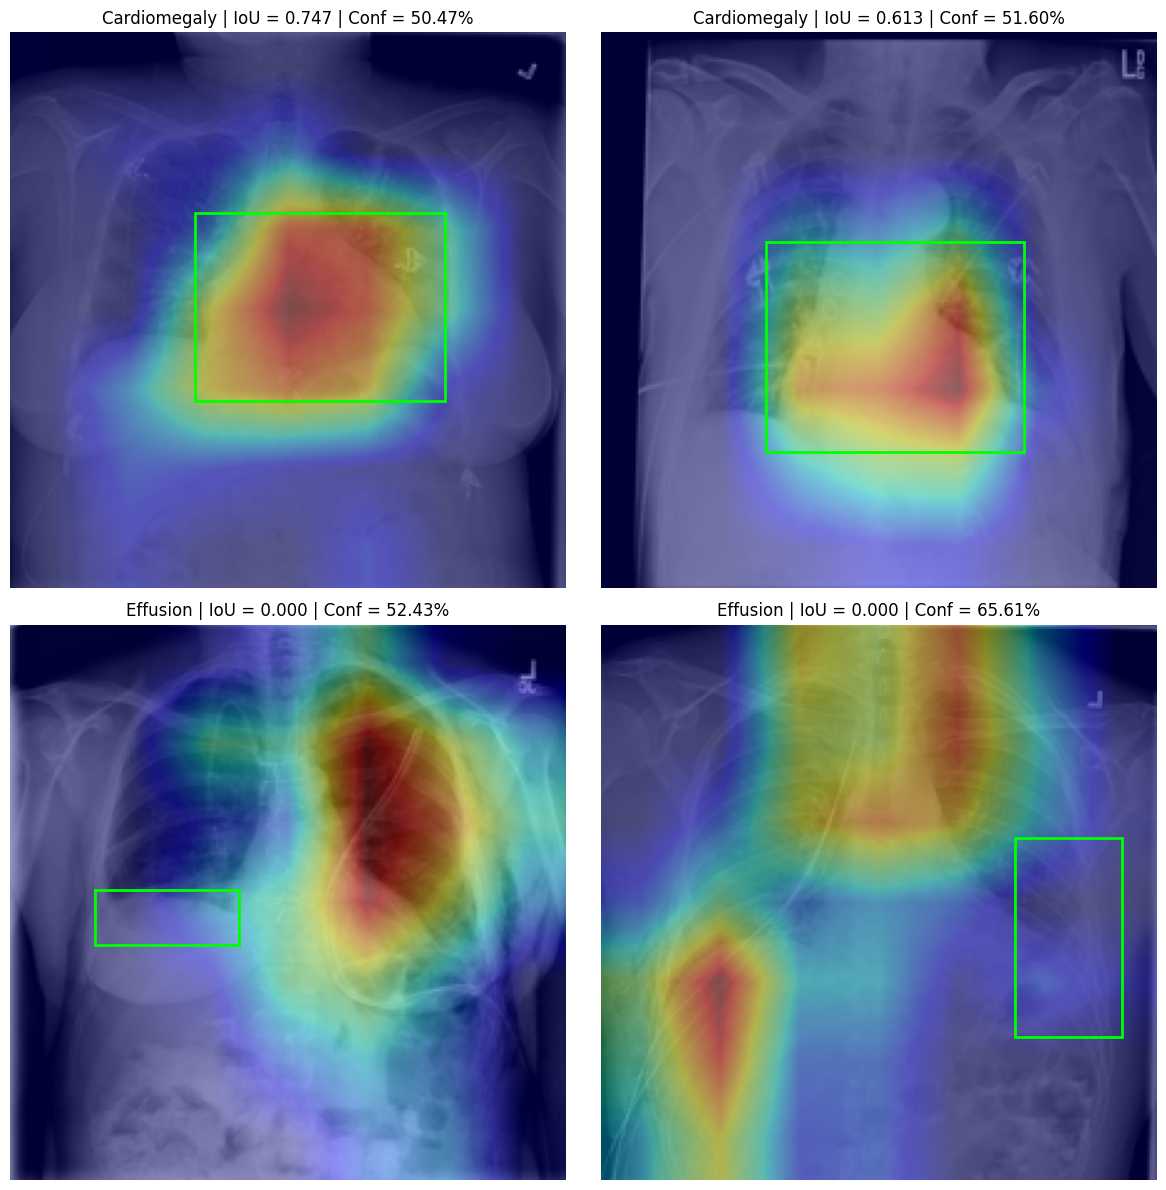

In [ ]:
# What this cell does: Plot examples with the strongest and weakest Grad-CAM/bounding-box overlap for visual inspection.
import matplotlib.patches as patches

if not results_df.empty:
    results_df_sorted = results_df.sort_values('iou', ascending=False)
    best_examples = results_df_sorted.head(2)
    worst_examples = results_df_sorted.tail(2)
    visualize_df = pd.concat([best_examples, worst_examples])

    fig, axes = plt.subplots(2, 2, figsize=(12, 12))

    for row_idx, (_, ex) in enumerate(visualize_df.iterrows()):
        idx, cls_name = int(ex['index']), ex['class']
        cls_idx = CLASSES.index(cls_name)
        img = all_imgs[idx]
        fname = ex['filename']

        heatmap = make_gradcam_heatmap(img[np.newaxis, ...], model, 'relu', cls_idx)
        heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))

        row = bbox_df[(bbox_df['Image Index'] == fname) & (bbox_df['Finding Label'] == cls_name)].iloc[0]
        x, y, w, h = row['x'] * scale, row['y'] * scale, row['w'] * scale, row['h'] * scale

        ax = axes[row_idx // 2, row_idx % 2]
        ax.imshow(img)
        ax.imshow(heatmap_resized, cmap='jet', alpha=0.4)
        rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='lime', facecolor='none')
        ax.add_patch(rect)
        ax.set_title(f"{cls_name} | IoU = {ex['iou']:.3f} | Conf = {ex['confidence']:.2%}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("No localization data available to plot.")

### Predict from an unlabeled image

Run the cell below to open a native Windows file chooser. Select an X-ray and the cell will show the image and its eight class probabilities inline. The cell finishes after prediction; it does not require a label file. It reuses the trained model in memory when available, or loads `final_model.keras`.

Image: C:\Users\LENOVO\Downloads\images.jpg
Prediction threshold: 50%


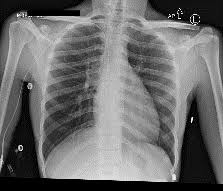

,Finding,Probability,Above threshold
0,Infiltrate,37.9%,False
1,Pneumonia,33.1%,False
2,Nodule,19.6%,False
3,Mass,17.6%,False
4,Cardiomegaly,15.0%,False
5,Atelectasis,10.9%,False
6,Pneumothorax,5.8%,False
7,Effusion,3.8%,False


No finding reached the threshold. This does not establish that the image is normal.


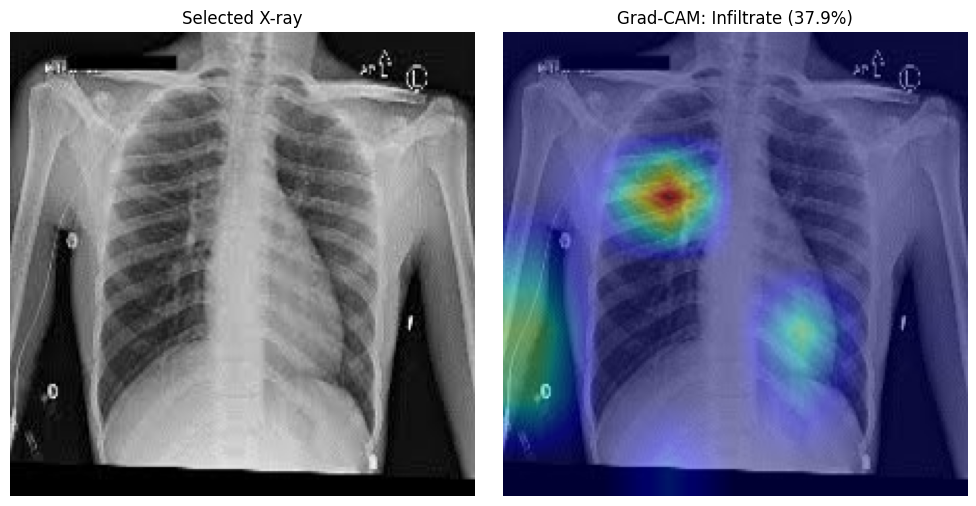

In [3]:
# What this cell does: Choose an unlabeled X-ray, prepare it for inference, display the model?s disease scores, and visualize Grad-CAM.
from pathlib import Path
import tkinter as tk
from tkinter import filedialog

import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from PIL import Image

PREDICTION_MODEL_PATH = Path("final_model.keras")
PREDICTION_THRESHOLD = 0.50
PREDICTION_IMAGE_SIZE = 224
PREDICTION_CLASSES = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltrate",
    "Mass", "Nodule", "Pneumonia", "Pneumothorax",
]

# Open the native file chooser without starting a persistent desktop event loop.
file_dialog_root = tk.Tk()
file_dialog_root.withdraw()
file_dialog_root.attributes("-topmost", True)
try:
    selected_image = filedialog.askopenfilename(
        parent=file_dialog_root,
        title="Choose an unlabeled chest X-ray",
        filetypes=[
            ("Image files", "*.png *.jpg *.jpeg *.bmp *.tif *.tiff"),
            ("All files", "*.*"),
        ],
    )
finally:
    file_dialog_root.destroy()

if not selected_image:
    print("No image selected. Run this cell again to choose an image.")
else:
    image_path = Path(selected_image)
    model_path = Path(PREDICTION_MODEL_PATH)
    if not model_path.is_file() and "BASE_DIR" in globals():
        model_path = Path(BASE_DIR) / model_path

    if not model_path.is_file() and not ("model" in globals() and hasattr(model, "predict")):
        raise FileNotFoundError(
            f"Model file not found: {model_path}. Run the training/save cells first."
        )

    # Match the training preprocessing: RGB, 224x224, and pixel values in [0, 1].
    with Image.open(image_path) as source_image:
        preview = source_image.convert("RGB")
        resized = preview.resize((PREDICTION_IMAGE_SIZE, PREDICTION_IMAGE_SIZE))
        image_batch = np.expand_dims(
            np.asarray(resized, dtype=np.float32) / 255.0,
            axis=0,
        )

    # Reuse the trained in-memory model for speed; load the saved model after a kernel restart.
    if "model" in globals() and hasattr(model, "predict"):
        inference_model = model
    else:
        inference_model = tf.keras.models.load_model(model_path, compile=False)

    scores = inference_model.predict(image_batch, verbose=0)[0]
    if len(scores) != len(PREDICTION_CLASSES):
        raise ValueError(
            f"Expected {len(PREDICTION_CLASSES)} model outputs, got {len(scores)}."
        )

    print(f"Image: {image_path}")
    print(f"Prediction threshold: {PREDICTION_THRESHOLD:.0%}")
    display(preview)
    prediction_table = pd.DataFrame({
        "Finding": PREDICTION_CLASSES,
        "Probability": scores,
    }).sort_values("Probability", ascending=False, ignore_index=True)
    prediction_table["Above threshold"] = (
        prediction_table["Probability"] >= PREDICTION_THRESHOLD
    )
    display(prediction_table.style.format({"Probability": "{:.1%}"}))

    predicted_findings = prediction_table.loc[
        prediction_table["Above threshold"], "Finding"
    ].tolist()
    if predicted_findings:
        print("Predicted findings:", ", ".join(predicted_findings))
    else:
        print(
            "No finding reached the threshold. This does not establish that the image is normal."
        )

    # Create a Grad-CAM overlay for the highest-scoring finding.
    # This helper keeps this cell usable after a kernel restart too.
    import cv2
    import matplotlib.pyplot as plt

    def prediction_gradcam(input_batch, keras_model, class_index):
        backbone = keras_model.get_layer("densenet121")
        conv_layer = backbone.get_layer("relu")
        grad_model = tf.keras.models.Model(
            backbone.input, [conv_layer.output, backbone.output]
        )
        with tf.GradientTape() as tape:
            conv_output, backbone_output = grad_model(input_batch, training=False)
            head_output = backbone_output
            after_backbone = False
            for layer in keras_model.layers:
                if layer.name == backbone.name:
                    after_backbone = True
                    continue
                if after_backbone:
                    head_output = layer(head_output, training=False)
            class_score = head_output[:, class_index]

        gradients = tape.gradient(class_score, conv_output)
        if gradients is None:
            raise RuntimeError("Could not compute Grad-CAM gradients for this model.")
        channel_weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
        heatmap = tf.reduce_sum(conv_output[0] * channel_weights, axis=-1)
        heatmap = tf.maximum(heatmap, 0)
        return (heatmap / (tf.reduce_max(heatmap) + 1e-8)).numpy()

    top_class_index = int(np.argmax(scores))
    heatmap = prediction_gradcam(image_batch, inference_model, top_class_index)
    heatmap = cv2.resize(heatmap, (PREDICTION_IMAGE_SIZE, PREDICTION_IMAGE_SIZE))
    heatmap_rgb = plt.cm.jet(heatmap)[..., :3]
    image_rgb = image_batch[0]
    overlay = np.clip(image_rgb * 0.6 + heatmap_rgb * 0.4, 0, 1)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(image_rgb)
    axes[0].set_title("Selected X-ray")
    axes[1].imshow(overlay)
    axes[1].set_title(
        f"Grad-CAM: {PREDICTION_CLASSES[top_class_index]} ({scores[top_class_index]:.1%})"
    )
    for axis in axes:
        axis.axis("off")
    plt.tight_layout()
    plt.show()
